In [ ]:
import shutil
#from google.colab import drive
from pathlib import Path

#drive.mount("/content/drive")

PROJ      = Path("/content/drive/MyDrive/dataset/Multiclass_Cyberbulling_dataset")
SAVE_ROOT = PROJ / "models"          # fine-tuned weights (big)
MIRROR    = PROJ / "results"         # prob_*.npy, history, csv, png (tiny)
for d in (PROJ, SAVE_ROOT, MIRROR):
    d.mkdir(parents=True, exist_ok=True)

# nb_dataset must already be in Drive; T2's DATA_DIR should point at it.
DRIVE_DATA = PROJ / "nb_dataset"
print(f"data   {DRIVE_DATA}  exists={DRIVE_DATA.exists()}")
if DRIVE_DATA.exists():
    print(f"       {sorted(f.name for f in DRIVE_DATA.glob('*'))}")
print(f"models {SAVE_ROOT}")
print(f"mirror {MIRROR}")

free = shutil.disk_usage("/content/drive/MyDrive").free / 1024**3
print(f"\nDrive free: {free:.1f} GiB")
print("fp32 all three = 2.33 GiB | fp16 all three = 1.16 GiB")
if free < 3:
    print("*** Under 3 GiB free — use SAVE_MODE='fp16', or 'best_only' to keep "
          "just the winning model.")

data   \content\drive\MyDrive\dataset\Multiclass_Cyberbulling_dataset\nb_dataset  exists=False
models \content\drive\MyDrive\dataset\Multiclass_Cyberbulling_dataset\models
mirror \content\drive\MyDrive\dataset\Multiclass_Cyberbulling_dataset\results

Drive free: 0.7 GiB
fp32 all three = 2.33 GiB | fp16 all three = 1.16 GiB
*** Under 3 GiB free — use SAVE_MODE='fp16', or 'best_only' to keep just the winning model.


In [ ]:
# ============================== CELL T1 ======================================
# Install. Safe to re-run; -q keeps it quiet. Works in Colab and in a plain
# kernel (no `!` magic, so this file is importable as-is).
# -----------------------------------------------------------------------------
import sys, subprocess

def pip(*args):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *args])

pip("transformers>=4.40", "tokenizers>=0.19", "sentencepiece", "protobuf")
pip("scikit-learn", "matplotlib", "pandas")

# BanglaBERT's model card requires csebuetnlp's normalizer, not plain NFC.
# Its authors report a measurable drop without it. If the git install fails
# (no git, no network) we fall back to NFC and print a loud warning, because
# that changes BanglaBERT's numbers and you must say so in the write-up.
HAVE_CSEB_NORM = False
try:
    from normalizer import normalize as _cseb_normalize
    HAVE_CSEB_NORM = True
except ImportError:
    try:
        pip("git+https://github.com/csebuetnlp/normalizer")
        from normalizer import normalize as _cseb_normalize
        HAVE_CSEB_NORM = True
    except Exception as e:
        print(f"csebuetnlp normalizer unavailable ({type(e).__name__}) "
              f"-> falling back to NFC for BanglaBERT")

import torch, transformers
print(f"torch {torch.__version__} | transformers {transformers.__version__}")
print(f"cuda: {torch.cuda.is_available()} "
      f"({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU only'})")
print(f"csebuetnlp normalizer: {HAVE_CSEB_NORM}")
if not torch.cuda.is_available():
    print("\n*** No GPU. Expect ~5-6 h PER MODEL. Runtime > Change runtime type "
          "> T4 GPU on Colab, or reduce MODELS in T5 to one.")


torch 2.11.0+cpu | transformers 5.15.0
cuda: False (CPU only)
csebuetnlp normalizer: True

*** No GPU. Expect ~5-6 h PER MODEL. Runtime > Change runtime type > T4 GPU on Colab, or reduce MODELS in T5 to one.


In [ ]:
import sys, subprocess
def pip(*args):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *args])

In [ ]:
pip("git+https://github.com/csebuetnlp/normalizer")
from normalizer import normalize as _cseb_normalize
HAVE_CSEB_NORM = True

In [ ]:
# ============================== CELL T2 ======================================
# Config + data pipeline. Reads the same nb_dataset/*.csv the CNN arm reads,
# so both arms see identical splits — the split was made once, on text_clean
# groups, and is frozen in those files.
# -----------------------------------------------------------------------------
import os, json, time, random, unicodedata, gc
from pathlib import Path
import numpy as np
import pandas as pd
import torch, transformers

PROJ      = Path(r"D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\transformer")
SAVE_ROOT = PROJ / "models"          # fine-tuned weights (big)
MIRROR    = PROJ / "results"         # prob_*.npy, history, csv, png (tiny)

# --- paths -------------------------------------------------------------------
DATA_DIR = PROJ / "nb_dataset"
OUTDIR   = PROJ / "outputs"; OUTDIR.mkdir(exist_ok=True, parents=True)
MIRROR.mkdir(parents=True, exist_ok=True) # Ensure MIRROR directory exists

SEED = 42

# --- knobs -------------------------------------------------------------------
MAX_TOK          = 64      # verified against the real length distribution below
LABEL_SMOOTH     = 0.05    # matches the CNN arm; absorbs the 2.82% label noise
EPOCHS           = 4
PATIENCE         = 2       # on val macro-F1
GRAD_CLIP        = 1.0
WARMUP_FRAC      = 0.10
TRAIN_ON_UNIQUE  = True    # see the note below
VAL_DEDUP        = False   # keep False: the CNN arm selected on the full val set
HONEST_N         = 6000    # train rows re-scored each epoch with dropout OFF
KEEP_STATE_ON    = "cpu"   # best weights held in RAM, not written to disk

# TRAIN_ON_UNIQUE: the CSVs contain a 2x oversample (26.96% of train rows are a
# second copy of another row). Oversampling was there to help a from-scratch
# model see rare classes more often. A pretrained transformer does not need it,
# and duplicates + class weights double-correct the same imbalance. Training on
# the 40,902 unique rows with freshly computed balanced weights is 27% less
# compute for the same information. Evaluation is unaffected either way — that
# is what keeps the comparison honest.

def seed_all(s=SEED):
    random.seed(s); np.random.seed(s)
    os.environ["PYTHONHASHSEED"] = str(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

seed_all()

# --- load --------------------------------------------------------------------
train = pd.read_csv(DATA_DIR / "train.csv")
val   = pd.read_csv(DATA_DIR / "val.csv")
test  = pd.read_csv(DATA_DIR / "test.csv")
print(f"train {len(train):,} | val {len(val):,} | test {len(test):,}")

classes     = sorted(train["label"].unique())
id_to_label = list(classes)
label_to_id = {l: i for i, l in enumerate(id_to_label)}
NUM_CLASSES = len(id_to_label)
print(f"classes: {id_to_label}")

# label_id in the CSV must agree with sorted-class order, or every number below
# is silently permuted relative to the CNN arm's confusion matrix.
for nm, df in (("train", train), ("val", val), ("test", test)):
    assert (df["label"].map(label_to_id).values == df["label_id"].values).all(), \
        f"{nm}: label_id disagrees with sorted(classes) order"
if (DATA_DIR / "label_mapping.json").exists():
    _m = json.loads((DATA_DIR / "label_mapping.json").read_text(encoding="utf-8"))
    print(f"label_mapping.json cross-check: OK  ({list(_m)[:3]}...)")

# --- raw text, NFC only ------------------------------------------------------
# `Sentence` is the untouched original. text_clean is NOT used here.
def prep(s):
    s = "" if pd.isna(s) else str(s)
    return unicodedata.normalize("NFC", s).strip()

for df in (train, val, test):
    df["text_tf"] = df["Sentence"].map(prep)
    assert (df["text_tf"].str.len() > 0).all(), "empty Sentence after NFC"

print("\nraw vs cleaned, first 3 test rows (they should differ):")
for i in range(3):
    print(f"  raw   : {test['text_tf'].iloc[i][:90]}")
    print(f"  clean : {str(test['text_clean'].iloc[i])[:90]}")

# --- the evaluation index, identical to the CNN arm --------------------------
KEEP    = np.flatnonzero(~test["text_clean"].duplicated().values)
KEEP_TR = np.flatnonzero(~train["text_clean"].duplicated().values)
assert len(KEEP) == 8764, f"KEEP is {len(KEEP)}, expected 8,764 — wrong CSVs?"
print(f"\neval on {len(KEEP):,} unique test comments (same index as the CNN arm)")

# --- training rows -----------------------------------------------------------
tr_idx = KEEP_TR if TRAIN_ON_UNIQUE else np.arange(len(train))
tr_txt = train["text_tf"].values[tr_idx]
tr_y   = train["label_id"].values[tr_idx].astype(np.int64)

va_idx = (np.flatnonzero(~val["text_clean"].duplicated().values) if VAL_DEDUP
          else np.arange(len(val)))
va_txt = val["text_tf"].values[va_idx]
va_y = val["label_id"].values[va_idx].astype(np.int64)

te_txt = test["text_tf"].values                     # full test; index with KEEP later
te_y   = test["label_id"].values.astype(np.int64)

print(f"train rows used {len(tr_y):,} | val {len(va_y):,} | test {len(te_y):,}")

# --- class weights, recomputed on the rows we actually train on --------------
# Reusing class_weights.json here would double-correct: those weights were fit
# to the oversampled distribution, which no longer applies once we de-duplicate.
cnt = np.bincount(tr_y, minlength=NUM_CLASSES).astype(np.float64)
cw  = len(tr_y) / (NUM_CLASSES * cnt)
cw  = cw / cw.mean()                                # mean 1 keeps loss scale comparable
print("\nclass counts / weights on the training rows used:")
for i in range(NUM_CLASSES):
    print(f"   {id_to_label[i]:<12} n={int(cnt[i]):>6,}  w={cw[i]:.3f}")

# --- honest-train subsample, fixed once so the curve is comparable per model --
_rs        = np.random.RandomState(SEED)
_hon       = _rs.choice(len(tr_y), size=min(HONEST_N, len(tr_y)), replace=False)
hon_txt    = tr_txt[_hon]
hon_y      = tr_y[_hon]

RESULTS_TF, HIST_TF, PROBS_TF = {}, {}, {}
print("\ndata pipeline ready")

SAVE_MODE = "fp16"      # "none"      nothing written (original behaviour)
                        # "fp16"      half precision, ~half the size.
                        #             Inference-identical for practical purposes;
                        #             see the tolerance note in T9.
                        # "fp32"      exact weights, resumable, 2.33 GB total
                        # "best_only" fp32, but only if this model beats every
                        #             model saved so far — keeps one directory

RESUME = True           # if a model directory already exists, skip retraining
                        # and load it. This is what makes a disconnect cheap:
                        # re-run T5 and it picks up where you left off.

print(f"SAVE_MODE={SAVE_MODE} | RESUME={RESUME} | SAVE_ROOT={SAVE_ROOT}")

train 55,999 | val 12,002 | test 11,999
classes: ['not bully', 'religious', 'sexual', 'threat', 'troll']
label_mapping.json cross-check: OK  (['label_to_id', 'id_to_label', 'classes_in_id_order']...)

raw vs cleaned, first 3 test rows (they should differ):
  raw   : ওরে জুতা মারো যে যেখানে ওরে পাওয় ,,,,নাস্তিক ছিঃ ছিঃ ছিঃ
  clean : ওরে জুতা মারো যে যেখানে ওরে পাওয় ,,নাস্তিক ছিঃ ছিঃ ছিঃ
  raw   : ভাই প্রত্যেকটা মানুষ জীবনে কোন না কোন ভুল করে থাকে আসলে আমি জানিনা এই অডিও কলটা সত্যি না ম
  clean : ভাই প্রত্যেকটা মানুষ জীবনে কোন না কোন ভুল করে থাকে আসলে আমি জানিনা এই অডিও কলটা সত্যি না ম
  raw   : এটাকে নাটক বলবো কিনা জানিনা কারন এটা আমাদের সমাজের বাস্তব চিত্রের প্রতিচ্ছবি নাটকের প্রত্য
  clean : এটাকে নাটক বলবো কিনা জানিনা কারন এটা আমাদের সমাজের বাস্তব চিত্রের প্রতিচ্ছবি নাটকের প্রত্য

eval on 8,764 unique test comments (same index as the CNN arm)
train rows used 40,902 | val 12,002 | test 11,999

class counts / weights on the training rows used:
   not bully    n=13,695  w=0.346
   rel

In [ ]:
# ============================== CELL T3 ======================================
# Dataset / collator / length check. Dynamic padding, so a 9-token comment
# costs 9 tokens and not 64 — this is where most of the speedup comes from.
# -----------------------------------------------------------------------------
from torch.utils.data import Dataset, DataLoader

class IdsDS(Dataset):
    def __init__(self, ids_list, y):
        self.ids, self.y = ids_list, y
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.ids[i], int(self.y[i])

def make_collate(pad_id):
    def collate(batch):
        seqs, ys = zip(*batch)
        m   = max(len(s) for s in seqs)
        inp = torch.full((len(seqs), m), pad_id, dtype=torch.long)
        att = torch.zeros((len(seqs), m), dtype=torch.long)
        for i, s in enumerate(seqs):
            n = len(s)
            inp[i, :n] = torch.tensor(s, dtype=torch.long)
            att[i, :n] = 1
        return inp, att, torch.tensor(ys, dtype=torch.long)
    return collate

def encode(tok, texts, max_len=MAX_TOK, bs=2000):
    out = []
    for i in range(0, len(texts), bs):
        out += tok(list(texts[i:i + bs]), truncation=True,
                   max_length=max_len, add_special_tokens=True)["input_ids"]
    return out

def length_report(tok, name):
    """Is MAX_TOK actually big enough? Truncating 5% of comments loses threats,
       which tend to sit at the end of a sentence."""
    n = [len(s) for s in encode(tok, te_txt, max_len=512)]
    n = np.array(n)
    p = {q: int(np.percentile(n, q)) for q in (50, 90, 95, 99)}
    frac = (n > MAX_TOK).mean() * 100
    print(f"   {name}: median {p[50]}  p90 {p[90]}  p95 {p[95]}  p99 {p[99]}  "
          f"max {n.max()}  | {frac:.2f}% truncated at MAX_TOK={MAX_TOK}")
    if frac > 5:
        print(f"   *** {frac:.1f}% truncated — raise MAX_TOK to {p[99]} "
              f"(cost scales ~linearly)")
    return p

print("subword length distribution on the test set")


subword length distribution on the test set


In [ ]:
import torch.nn as nn
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          AutoConfig, get_linear_schedule_with_warmup)
from sklearn.metrics import (f1_score, classification_report, confusion_matrix,
                             roc_curve, auc)
from sklearn.preprocessing import label_binarize

DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = torch.cuda.is_available()

def _autocast():
    if not AMP:
        return torch.autocast("cpu", enabled=False)
    try:
        return torch.amp.autocast("cuda", dtype=torch.float16)
    except AttributeError:
        return torch.cuda.amp.autocast()

def _scaler():
    if not AMP:
        return None
    try:
        return torch.amp.GradScaler("cuda")
    except AttributeError:
        return torch.cuda.amp.GradScaler()

@torch.no_grad()
def evaluate(model, loader, lossfn, want_prob=False):
    model.eval()
    tot, n, preds, probs = 0.0, 0, [], []
    for inp, att, y in loader:
        inp, att, y = inp.to(DEV), att.to(DEV), y.to(DEV)
        with _autocast():
            logits = model(input_ids=inp, attention_mask=att).logits
        logits = logits.float()
        tot += lossfn(logits, y).item() * y.size(0); n += y.size(0)
        if want_prob:
            probs.append(torch.softmax(logits, -1).cpu().numpy())
        preds.append(logits.argmax(-1).cpu().numpy())
    pred = np.concatenate(preds)
    prob = np.concatenate(probs) if want_prob else None
    return tot / n, pred, prob
import json

def model_dir(slug):
    return SAVE_ROOT / f"{slug}_s{SEED}"

def save_finetuned(model, tok, slug, row, hist, mode, normalizer_used):
    """Write the model in HuggingFace format plus everything needed to reproduce
       inference. Returns the directory, or None if nothing was written."""
    if mode == "none":
        return None

    if mode == "best_only":
        best = max((r["macro_F1"] for r in RESULTS_TF.values()), default=-1)
        if row["macro_F1"] < best:
            print(f"save skipped: macro-F1 {row['macro_F1']:.4f} < best "
                  f"{best:.4f} (SAVE_MODE='best_only')")
            return None
        for old in SAVE_ROOT.glob("*_s*"):
            if old.name != model_dir(slug).name and (old / "config.json").exists():
                shutil.rmtree(old, ignore_errors=True)
                print(f"removed superseded {old.name}")

    d = model_dir(slug)
    d.mkdir(parents=True, exist_ok=True)

    if mode == "fp16":
        # cast a COPY of the state dict — do not call model.half(), which
        # mutates the live model and corrupts any evaluation that follows
        sd = {k: (v.half() if v.is_floating_point() else v)
              for k, v in model.state_dict().items()}
        model.save_pretrained(d, state_dict=sd, safe_serialization=True)
    else:
        model.save_pretrained(d, safe_serialization=True)
    tok.save_pretrained(d)

    # Without this file a reloaded model silently preprocesses differently.
    # BanglaBERT's normalizer is an EXTERNAL package, not part of the tokenizer,
    # so nothing in the saved tokenizer records that it was applied.
    (d / "inference_config.json").write_text(json.dumps({
        "slug": slug, "hf_id": row["hf_id"], "seed": SEED,
        "id_to_label": id_to_label, "num_classes": NUM_CLASSES,
        "max_tok": MAX_TOK, "text_column": "Sentence",
        "text_normalisation": "NFC" + (" + csebuetnlp.normalizer"
                                       if normalizer_used else ""),
        "csebuetnlp_normalizer_used": bool(normalizer_used),
        "label_smoothing": LABEL_SMOOTH, "trained_on_unique": TRAIN_ON_UNIQUE,
        "class_weights": [float(x) for x in cw],
        "save_dtype": "float16" if mode == "fp16" else "float32",
        "best_epoch": row["best_epoch"], "val_macro_f1_selected": row["macro_F1"],
        "transformers": transformers.__version__, "torch": torch.__version__,
    }, indent=2, ensure_ascii=False), encoding="utf-8")

    (d / "history.json").write_text(json.dumps(hist, indent=2), encoding="utf-8")
    (d / "run_row.json").write_text(json.dumps(row, indent=2, default=float,
                                               ensure_ascii=False),
                                    encoding="utf-8")

    mb = sum(f.stat().st_size for f in d.rglob("*") if f.is_file()) / 1024**2
    print(f"saved -> {d}  ({mb:.0f} MB, {mode})")
    print("   Drive sync can lag a minute or two on a 1 GB write; let the cell "
          "finish before disconnecting.")
    return d


def load_finetuned(slug, dtype=None):
    """Reload a saved model. dtype=None loads into fp32 regardless of how it
       was stored, which is what you want for exact comparison."""
    d = model_dir(slug)
    cfgp = d / "inference_config.json"
    if not (d / "config.json").exists():
        return None, None, None
    tok = AutoTokenizer.from_pretrained(d)
    kw  = {} if dtype is None else {"torch_dtype": dtype}
    m   = AutoModelForSequenceClassification.from_pretrained(d, **kw).to(DEV)
    m.eval()
    cfg = json.loads(cfgp.read_text(encoding="utf-8")) if cfgp.exists() else {}
    return m, tok, cfg

def train_transformer(slug, hf_id, lr=2e-5, batch=32, epochs=EPOCHS,
                      normalizer=None, accum=1):
    t0 = time.time()
    seed_all()
    print(f"\n{'='*72}\n{slug}  ({hf_id})\n{'='*72}")

    if RESUME and (model_dir(slug) / "config.json").exists():
         print(f"found {model_dir(slug).name} — loading instead of retraining.")
         print("   set RESUME=False to force a fresh run.")
         _m, _t, _c = load_finetuned(slug)
         _hist = json.loads((model_dir(slug) / "history.json").read_text())
         _row  = json.loads((model_dir(slug) / "run_row.json").read_text())
         # re-score so PROBS_TF is populated for T6/T7/T8
         _nz   = ((lambda a: [normalizer(t) for t in a]) if normalizer
                  else (lambda a: list(a)))
         _ids  = encode(_t, _nz(te_txt))
         _dl   = DataLoader(IdsDS(_ids, te_y), batch_size=128,
                            collate_fn=make_collate(_t.pad_token_id))
         _lf   = nn.CrossEntropyLoss(
                     weight=torch.tensor(cw, dtype=torch.float32, device=DEV),
                     label_smoothing=LABEL_SMOOTH)
         _, _p, _pr = evaluate(_m, _dl, _lf, want_prob=True)
         RESULTS_TF[slug], HIST_TF[slug], PROBS_TF[slug] = _row, _hist, _pr
         np.save(OUTDIR / f"prob_transformer_{slug}_s{SEED}.npy", _pr)
         del _m; gc.collect(); torch.cuda.empty_cache()
         return _hist

    tok = AutoTokenizer.from_pretrained(hf_id)
    print(f"tokenizer: {type(tok).__name__} | vocab {tok.vocab_size:,} | "
          f"pad_id {tok.pad_token_id}")
    length_report(tok, slug)

    # per-model text normalisation (BanglaBERT wants csebuetnlp's, others NFC)
    nz = (lambda a: [normalizer(t) for t in a]) if normalizer else (lambda a: list(a))
    tr_ids  = encode(tok, nz(tr_txt))
    va_ids  = encode(tok, nz(va_txt))
    te_ids  = encode(tok, nz(te_txt))
    hon_ids = encode(tok, nz(hon_txt))

    coll = make_collate(tok.pad_token_id)
    g = torch.Generator(); g.manual_seed(SEED)
    dl_tr  = DataLoader(IdsDS(tr_ids,  tr_y),  batch_size=batch, shuffle=True,
                        collate_fn=coll, generator=g, drop_last=False)
    dl_va  = DataLoader(IdsDS(va_ids,  va_y),  batch_size=128, collate_fn=coll)
    dl_te  = DataLoader(IdsDS(te_ids,  te_y),  batch_size=128, collate_fn=coll)
    dl_hon = DataLoader(IdsDS(hon_ids, hon_y), batch_size=128, collate_fn=coll)

    cfg = AutoConfig.from_pretrained(hf_id, num_labels=NUM_CLASSES,
                                     id2label={i: l for i, l in enumerate(id_to_label)},
                                     label2id=label_to_id)
    model = AutoModelForSequenceClassification.from_pretrained(hf_id, config=cfg)
    model.to(DEV)
    n_par = sum(p.numel() for p in model.parameters())
    n_emb = sum(p.numel() for n, p in model.named_parameters() if "embeddings" in n)
    print(f"params {n_par/1e6:.1f}M  (embeddings {n_emb/1e6:.1f}M, "
          f"encoder+head {(n_par-n_emb)/1e6:.1f}M)")

    # same loss family as the CNN arm: class-weighted CE with label smoothing
    W      = torch.tensor(cw, dtype=torch.float32, device=DEV)
    lossfn = nn.CrossEntropyLoss(weight=W, label_smoothing=LABEL_SMOOTH)

    # no weight decay on biases and LayerNorm — standard for BERT fine-tuning
    nd = ["bias", "LayerNorm.weight", "layer_norm.weight"]
    groups = [
        {"params": [p for n, p in model.named_parameters()
                    if not any(k in n for k in nd)], "weight_decay": 0.01},
        {"params": [p for n, p in model.named_parameters()
                    if any(k in n for k in nd)], "weight_decay": 0.0},
    ]
    opt   = torch.optim.AdamW(groups, lr=lr, eps=1e-8)
    steps = (len(dl_tr) // accum) * epochs
    sch   = get_linear_schedule_with_warmup(opt, int(WARMUP_FRAC * steps), steps)
    scaler = _scaler()
    print(f"lr {lr} | batch {batch}x{accum} | {len(dl_tr)} steps/epoch | "
          f"{steps} total | amp {AMP}")

    h = {k: [] for k in ("loss", "acc", "val_loss", "val_acc", "val_macro_f1",
                         "h_tr_acc", "h_tr_f1", "lr")}
    best_f1, best_state, best_ep, bad = -1.0, None, -1, 0

    for ep in range(1, epochs + 1):
        model.train()
        run, seen, corr = 0.0, 0, 0
        opt.zero_grad(set_to_none=True)
        for step, (inp, att, y) in enumerate(dl_tr):
            inp, att, y = inp.to(DEV), att.to(DEV), y.to(DEV)
            with _autocast():
                logits = model(input_ids=inp, attention_mask=att).logits
                loss   = lossfn(logits.float(), y) / accum
            if scaler:
                scaler.scale(loss).backward()
            else:
                loss.backward()
            if (step + 1) % accum == 0 or (step + 1) == len(dl_tr):
                if scaler:
                    scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                if scaler:
                    scaler.step(opt); scaler.update()
                else:
                    opt.step()
                sch.step(); opt.zero_grad(set_to_none=True)
            run  += loss.item() * accum * y.size(0)
            corr += (logits.float().argmax(-1) == y).sum().item()
            seen += y.size(0)

        # train metrics here are dropout-ON running averages, exactly like Keras
        h["loss"].append(run / seen)
        h["acc"].append(corr / seen)
        h["lr"].append(sch.get_last_lr()[0])

        vl, vp, _ = evaluate(model, dl_va, lossfn)
        vf1 = f1_score(va_y, vp, average="macro", zero_division=0)
        h["val_loss"].append(vl)
        h["val_acc"].append(float((vp == va_y).mean()))
        h["val_macro_f1"].append(float(vf1))

        # honest train: dropout OFF, unique rows, one clean pass — the only
        # train number that is on the same footing as the val number
        _, hp, _ = evaluate(model, dl_hon, lossfn)
        h["h_tr_acc"].append(float((hp == hon_y).mean()))
        h["h_tr_f1"].append(float(f1_score(hon_y, hp, average="macro",
                                           zero_division=0)))

        print(f"  ep {ep}/{epochs}  loss {h['loss'][-1]:.4f}  "
              f"val_loss {vl:.4f}  val_acc {h['val_acc'][-1]*100:.2f}%  "
              f"val_F1 {vf1:.4f}  h_tr_F1 {h['h_tr_f1'][-1]:.4f}  "
              f"gap {(h['h_tr_f1'][-1]-vf1)*100:+.2f} pp")

        if ep == 1 and vf1 < 0.25:
            print("  *** val macro-F1 near chance after epoch 1 — this run has "
                  f"collapsed. Retry with lr={lr/2:g}.")

        if vf1 > best_f1:
            best_f1, best_ep, bad = vf1, ep, 0
            best_state = {k: v.detach().to(KEEP_STATE_ON).clone()
                          for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f"  early stop (no val macro-F1 gain in {PATIENCE} epochs)")
                break

    # restore best. HF Trainer's load_best_model_at_end is the equivalent; doing
    # it explicitly means the reported numbers cannot come from the last epoch.
    model.load_state_dict({k: v.to(DEV) for k, v in best_state.items()})
    print(f"  restored epoch {best_ep} (val macro-F1 {best_f1:.4f})")

    _, te_pred, te_prob = evaluate(model, dl_te, lossfn, want_prob=True)
    _, hp, _            = evaluate(model, dl_hon, lossfn)

    yt, yp = te_y[KEEP], te_pred[KEEP]
    acc_te = float((yt == yp).mean())
    f1m    = f1_score(yt, yp, average="macro", zero_division=0)
    per    = f1_score(yt, yp, average=None, labels=range(NUM_CLASSES),
                      zero_division=0)
    acc_tr = float((hp == hon_y).mean())

    slope = float("nan")
    if len(h["h_tr_f1"]) >= 3:
        gap = (np.array(h["h_tr_f1"]) - np.array(h["val_macro_f1"])) * 100
        slope = float(np.polyfit(np.arange(len(gap)), gap, 1)[0])

    mins = (time.time() - t0) / 60
    print(f"\n{slug}: test acc {acc_te*100:.2f}%  macro-F1 {f1m:.4f}  "
          f"(on {len(KEEP):,} unique comments)")
    print(f"honest train acc {acc_tr*100:.2f}%  gap {(acc_tr-acc_te)*100:+.1f} pp  "
          f"slope {slope:+.4f} pp/epoch  |  {mins:.1f} min")
    print(classification_report(yt, yp, target_names=id_to_label, digits=4,
                                zero_division=0))
    print(pd.DataFrame(confusion_matrix(yt, yp, labels=range(NUM_CLASSES)),
                       index=id_to_label, columns=id_to_label).to_string())

    np.save(OUTDIR / f"prob_transformer_{slug}_s{SEED}.npy", te_prob)

    row = {"model": slug, "algo": "transformer", "seed": SEED, "hf_id": hf_id,
           "train_acc_unique": acc_tr, "test_acc": acc_te,
           "gap_pp": (acc_tr - acc_te) * 100, "gap_slope": slope,
           "macro_F1": f1m,
           "weighted_F1": f1_score(yt, yp, average="weighted", zero_division=0),
           **{f"F1_{id_to_label[i]}": per[i] for i in range(NUM_CLASSES)},
           "params": n_par, "epochs_run": len(h["loss"]), "best_epoch": best_ep,
           "lr": lr, "batch": batch * accum, "max_tok": MAX_TOK,
           "min": round(mins, 1)}
    RESULTS_TF[slug] = row
    HIST_TF[slug]    = h
    PROBS_TF[slug]   = te_prob
    pd.DataFrame(list(RESULTS_TF.values())).to_csv(
        OUTDIR / "transformer_runs.csv", index=False)
    save_finetuned(model, tok, slug, row, h, SAVE_MODE,
                    normalizer_used=normalizer is not None)
    (OUTDIR / f"history_{slug}_s{SEED}.json").write_text(json.dumps(h, indent=2))

    del model, opt, best_state
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return h

The installed version of bitsandbytes was compiled without GPU support. 8-bit optimizers, 8-bit multiplication, and GPU quantization are unavailable.


In [ ]:
def run_safe(slug):
    try:
        return train_transformer(slug, **MODELS[slug])
    except torch.cuda.OutOfMemoryError:
        print(f"\n{slug}: CUDA OOM. Runtime > Restart, then re-run — RESUME will "
              f"skip whatever already saved.")
        print("   Or reduce: batch=16 with accum=2 (keeps effective batch 32).")
        gc.collect(); torch.cuda.empty_cache()
    except KeyboardInterrupt:
        print(f"\n{slug}: interrupted. Nothing saved for this model; earlier "
              f"models are intact in Drive.")
    return None

In [ ]:
# ============================== CELL T5 ======================================
# The three models. Run one cell at a time so a download failure or an OOM does
# not cost you the runs that already succeeded.
#
# WHY THESE THREE
#  banglabert  monolingual Bangla ELECTRA. 32k Bangla-only subwords, so it
#              spends its embedding budget entirely on your language — the
#              lightest of the three and usually the strongest on Bangla.
#  muril       the only one pretrained on TRANSLITERATED Indic text. Your
#              comments are code-mixed (Banglish), which is exactly the case
#              the other two were never trained for.
#  xlmr        the standard multilingual baseline. Reviewers expect it; it is
#              what makes the other two numbers legible.
# -----------------------------------------------------------------------------
def _bnorm(t):
    return _cseb_normalize(t) if HAVE_CSEB_NORM else t

MODELS = {
    "banglabert": dict(hf_id="csebuetnlp/banglabert",     lr=3e-5, batch=32,
                       normalizer=_bnorm),
    "muril":      dict(hf_id="google/muril-base-cased",   lr=2e-5, batch=32,
                       normalizer=None),
    "xlmr":       dict(hf_id="xlm-roberta-base",          lr=2e-5, batch=32,
                       normalizer=None),
}

In [ ]:
h_bb = train_transformer("banglabert", **MODELS["banglabert"])


banglabert  (csebuetnlp/banglabert)
tokenizer: BertTokenizer | vocab 32,000 | pad_id 0
   banglabert: median 15  p90 51  p95 78  p99 208  max 512  | 6.94% truncated at MAX_TOK=64
   *** 6.9% truncated — raise MAX_TOK to 208 (cost scales ~linearly)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
classifier.dense.bias                             | MISSING    | 
classifier.dense.weight                           | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


params 110.6M  (embeddings 25.0M, encoder+head 85.6M)
lr 3e-05 | batch 32x1 | 1279 steps/epoch | 5116 total | amp False
  ep 1/4  loss 0.9843  val_loss 0.6653  val_acc 84.56%  val_F1 0.8424  h_tr_F1 0.8627  gap +2.04 pp
  ep 2/4  loss 0.6327  val_loss 0.6660  val_acc 85.92%  val_F1 0.8546  h_tr_F1 0.9177  gap +6.31 pp
  ep 3/4  loss 0.5421  val_loss 0.6414  val_acc 87.08%  val_F1 0.8676  h_tr_F1 0.9505  gap +8.29 pp
  ep 4/4  loss 0.4811  val_loss 0.6617  val_acc 87.20%  val_F1 0.8684  h_tr_F1 0.9598  gap +9.14 pp
  restored epoch 4 (val macro-F1 0.8684)

banglabert: test acc 87.63%  macro-F1 0.8678  (on 8,764 unique comments)
honest train acc 96.67%  gap +9.0 pp  slope +2.3275 pp/epoch  |  260.3 min
              precision    recall  f1-score   support

   not bully     0.9043    0.9052    0.9048      2934
   religious     0.8812    0.9267    0.9034      1241
      sexual     0.8552    0.8586    0.8569      1747
      threat     0.8142    0.8347    0.8243       357
       troll     0.

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved -> D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\transformer\models\banglabert_s42  (212 MB, fp16)
   Drive sync can lag a minute or two on a 1 GB write; let the cell finish before disconnecting.


In [ ]:
h_mu = train_transformer("muril", **MODELS["muril"])


muril  (google/muril-base-cased)
tokenizer: BertTokenizer | vocab 197,258 | pad_id 0
   muril: median 16  p90 56  p95 87  p99 221  max 512  | 7.86% truncated at MAX_TOK=64
   *** 7.9% truncated — raise MAX_TOK to 221 (cost scales ~linearly)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

params 237.6M  (embeddings 151.9M, encoder+head 85.6M)
lr 2e-05 | batch 32x1 | 1279 steps/epoch | 5116 total | amp False


C:\Users\pciuc\miniconda3\lib\site-packages\huggingface_hub\file_download.py:746: UserWarning: Not enough free disk space to download the file. The expected file size is: 953.42 MB. The target location C:\Users\pciuc\.cache\huggingface\hub\models--google--muril-base-cased\blobs only has 303.19 MB free disk space.
  warnings.warn(


model.safetensors: reconstructing file:   0%|          |  0.00B /  953MB            

model.safetensors: downloading bytes:           |  0.00B            

  ep 1/4  loss 1.2523  val_loss 0.7878  val_acc 80.89%  val_F1 0.8055  h_tr_F1 0.8201  gap +1.46 pp
  ep 2/4  loss 0.7362  val_loss 0.6830  val_acc 83.99%  val_F1 0.8331  h_tr_F1 0.8708  gap +3.77 pp
  ep 3/4  loss 0.6295  val_loss 0.6608  val_acc 85.19%  val_F1 0.8482  h_tr_F1 0.9138  gap +6.56 pp
  ep 4/4  loss 0.5752  val_loss 0.6803  val_acc 85.32%  val_F1 0.8512  h_tr_F1 0.9263  gap +7.51 pp
  restored epoch 4 (val macro-F1 0.8512)

muril: test acc 85.54%  macro-F1 0.8472  (on 8,764 unique comments)
honest train acc 93.18%  gap +7.6 pp  slope +2.0925 pp/epoch  |  298.3 min
              precision    recall  f1-score   support

   not bully     0.8863    0.8851    0.8857      2934
   religious     0.9116    0.9138    0.9127      1241
      sexual     0.8389    0.8403    0.8396      1747
      threat     0.7401    0.8375    0.7858       357
       troll     0.8206    0.8044    0.8124      2485

    accuracy                         0.8554      8764
   macro avg     0.8395    0.8562  

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved -> D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\transformer\models\muril_s42  (459 MB, fp16)
   Drive sync can lag a minute or two on a 1 GB write; let the cell finish before disconnecting.


In [ ]:
h_xr = train_transformer("xlmr", **MODELS["xlmr"])


xlmr  (xlm-roberta-base)
tokenizer: XLMRobertaTokenizer | vocab 250,002 | pad_id 1
   xlmr: median 21  p90 72  p95 112  p99 289  max 512  | 11.93% truncated at MAX_TOK=64
   *** 11.9% truncated — raise MAX_TOK to 289 (cost scales ~linearly)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


params 278.0M  (embeddings 192.4M, encoder+head 85.6M)
lr 2e-05 | batch 32x1 | 1279 steps/epoch | 5116 total | amp False
  ep 1/4  loss 1.0885  val_loss 0.7772  val_acc 79.45%  val_F1 0.7866  h_tr_F1 0.7954  gap +0.87 pp
  ep 2/4  loss 0.7720  val_loss 0.7132  val_acc 82.19%  val_F1 0.8110  h_tr_F1 0.8420  gap +3.11 pp
  ep 3/4  loss 0.6982  val_loss 0.6965  val_acc 83.48%  val_F1 0.8293  h_tr_F1 0.8823  gap +5.30 pp
  ep 4/4  loss 0.6405  val_loss 0.7027  val_acc 83.74%  val_F1 0.8313  h_tr_F1 0.8965  gap +6.52 pp
  restored epoch 4 (val macro-F1 0.8313)

xlmr: test acc 83.82%  macro-F1 0.8292  (on 8,764 unique comments)
honest train acc 90.37%  gap +6.5 pp  slope +1.9139 pp/epoch  |  359.7 min
              precision    recall  f1-score   support

   not bully     0.8801    0.8654    0.8727      2934
   religious     0.8665    0.9098    0.8876      1241
      sexual     0.8142    0.8351    0.8245      1747
      threat     0.7157    0.8319    0.7694       357
       troll     0.8113 

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved -> D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\transformer\models\xlmr_s42  (547 MB, fp16)
   Drive sync can lag a minute or two on a 1 GB write; let the cell finish before disconnecting.


In [ ]:
# =============================================================================
#  CELL T5S - MULTI-SEED RUNS for the two models the XAI comparison rests on.
#
#  WHY THIS EXISTS
#  The whole X9 cross-model comparison asks "does the runner-up reach its
#  accuracy using the same evidence as the winner?". That question is only
#  meaningful if "winner" and "runner-up" are stable labels. You already
#  measured that six Keras architectures differed by 1.0pp macro-F1 and called
#  it seed noise, correctly. If BanglaBERT beats MuRIL by a similar margin at
#  one seed, the ranking could be a coin flip and a reviewer who read your own
#  architecture-noise finding will say so.
#
#  Two extra seeds each, roughly 80 minutes on a T4. XLM-R is deliberately left
#  at one seed: it is the citable baseline, not part of the comparison.
#
#  ---------------------------------------------------------------------------
#  RUN THIS AFTER T1-T5c, IN THE SAME SESSION
#  ---------------------------------------------------------------------------
#  It calls the existing train_transformer(), so everything (data, KEEP, class
#  weights, MAX_TOK, label smoothing) is inherited unchanged. That is the point:
#  the only thing varying across these runs is the seed.
#
#  ---------------------------------------------------------------------------
#  TWO THINGS THIS CELL DELIBERATELY PROTECTS
#  ---------------------------------------------------------------------------
#  1. YOUR SEED-42 CHECKPOINTS. The XAI arm (X1M) asserts that the checkpoint on
#     disk reproduces prob_transformer_<slug>_s42.npy. If a seed-1 run overwrote
#     models/banglabert_s42/, that assertion would start failing and your
#     finished XAI work would be invalidated. So SAVE_MODE is forced to "none"
#     for these runs: they exist to produce metrics and probability files, not
#     weights. You never need to explain a seed-1 model.
#  2. transformer_runs.csv, which train_transformer() rewrites on every call. It
#     keys rows on (model, seed), but RESULTS_TF is keyed on slug ALONE, so a
#     second seed would silently replace the seed-42 row in memory. This cell
#     snapshots and restores RESULTS_TF around each run and keeps its own
#     accumulator.
# =============================================================================

EXTRA_SEEDS = [1, 2]
SEED_MODELS = ["banglabert", "muril"]

import copy, json, time
import numpy as np
import pandas as pd

for _n in ("train_transformer", "MODELS", "RESULTS_TF", "SEED", "OUTDIR"):
    assert _n in globals(), (
        f"{_n} is missing. Run T1 through T5c first: this cell reuses that "
        f"pipeline rather than redefining it, so the seeds are the only thing "
        f"that changes.")

_BASE_SEED = SEED
_SAVE_MODE_BEFORE = globals().get("SAVE_MODE", "none")
SAVE_MODE = "none"          # see note 1 above. Do not change this.
print(f"base seed {_BASE_SEED} | extra seeds {EXTRA_SEEDS} | "
      f"SAVE_MODE forced to 'none' (protecting the s{_BASE_SEED} checkpoints)")

# collect the seed-42 rows that already exist, so the summary spans all seeds
_ALL = {}
for _s in SEED_MODELS:
    if _s in RESULTS_TF:
        _ALL[(_s, _BASE_SEED)] = dict(RESULTS_TF[_s])
    else:
        print(f"   *** no in-session result for {_s} at seed {_BASE_SEED}; it "
              f"will be read from transformer_runs.csv if present")

_t0 = time.time()
for _seed in EXTRA_SEEDS:
    for _slug in SEED_MODELS:
        print(f"\n{'='*70}\n{_slug}  seed {_seed}\n{'='*70}")
        SEED = _seed                      # train_transformer reads module SEED
        seed_all(_seed)                   # and re-seeds torch/np/random itself
        _keep = copy.deepcopy(RESULTS_TF)  # note 2: protect the s42 row
        try:
            train_transformer(_slug, **MODELS[_slug])
            _ALL[(_slug, _seed)] = dict(RESULTS_TF[_slug])
        except Exception as e:
            print(f"*** {_slug} s{_seed} FAILED: {type(e).__name__}: {e}")
            print("    Continuing. A missing seed is a limitation you can write "
                  "up; a corrupted seed-42 result is not.")
        finally:
            RESULTS_TF.clear()
            RESULTS_TF.update(_keep)
            if (_slug, _seed) in _ALL:
                RESULTS_TF[f"{_slug}_s{_seed}"] = _ALL[(_slug, _seed)]

SEED = _BASE_SEED                          # restore, or later cells drift
SAVE_MODE = _SAVE_MODE_BEFORE
print(f"\nall seed runs done in {(time.time()-_t0)/60:.1f} min. "
      f"SEED restored to {SEED}.")

# --------------------------------------------------- the number for the paper
# Report mean +- std across seeds, never a single seed's value, and do not bold
# a winner whose intervals overlap.
_rows = []
for (_slug, _sd), _r in sorted(_ALL.items()):
    _rows.append({"model": _slug, "seed": _sd,
                  "macro_F1": _r["macro_F1"], "test_acc": _r["test_acc"],
                  **{k: v for k, v in _r.items() if k.startswith("F1_")}})
SEEDRUNS = pd.DataFrame(_rows)
SEEDRUNS.to_csv(OUTDIR / "seed_runs.csv", index=False)

_agg = (SEEDRUNS.groupby("model")["macro_F1"]
        .agg(n="count", mean="mean", std="std", lo="min", hi="max")
        .reset_index())
print("\nmacro-F1 across seeds")
print(_agg.to_string(index=False))

if len(_agg) == 2:
    _a, _b = _agg.iloc[0], _agg.iloc[1]
    _gap = abs(_a["mean"] - _b["mean"]) * 100
    _noise = float(np.nanmax([_a["std"], _b["std"]])) * 100
    print(f"\ngap between means {_gap:.2f} pp | largest per-model std "
          f"{_noise:.2f} pp")
    if np.isnan(_noise):
        print("only one seed per model: cannot separate signal from noise yet.")
    elif _gap > 2 * _noise:
        print("The gap is larger than twice the seed noise, so the ranking is "
              "stable. X9's winner-vs-runner-up framing holds as written.")
    else:
        print("The gap is WITHIN seed noise. Do not call one model better. "
              "Rewrite the X9 framing as: two architectures reach "
              "statistically indistinguishable accuracy while relying on "
              "different lexical evidence. That is a stronger and more "
              "interesting claim than a ranking, and X9 already measures it.")

print("\nNote: these runs saved no checkpoints, so they cannot be explained "
      "with X1M. That is intended. Attribution stays on the seed-42 models.")

base seed 42 | extra seeds [1, 2] | SAVE_MODE forced to 'none' (protecting the s42 checkpoints)

banglabert  seed 1

banglabert  (csebuetnlp/banglabert)
tokenizer: BertTokenizer | vocab 32,000 | pad_id 0
   banglabert: median 15  p90 51  p95 78  p99 208  max 512  | 6.94% truncated at MAX_TOK=64
   *** 6.9% truncated — raise MAX_TOK to 208 (cost scales ~linearly)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
classifier.dense.bias                             | MISSING    | 
classifier.dense.weight                           | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


params 110.6M  (embeddings 25.0M, encoder+head 85.6M)
lr 3e-05 | batch 32x1 | 1279 steps/epoch | 5116 total | amp False
  ep 1/4  loss 0.9749  val_loss 0.6430  val_acc 84.73%  val_F1 0.8440  h_tr_F1 0.8647  gap +2.07 pp
  ep 2/4  loss 0.6428  val_loss 0.6347  val_acc 86.22%  val_F1 0.8597  h_tr_F1 0.9089  gap +4.93 pp
  ep 3/4  loss 0.5481  val_loss 0.6314  val_acc 87.64%  val_F1 0.8740  h_tr_F1 0.9446  gap +7.07 pp


In [ ]:
import sys, json
import numpy as np, pandas as pd
import matplotlib

IN_NOTEBOOK = any(m in sys.modules for m in ("google.colab", "ipykernel"))

if not IN_NOTEBOOK:
    matplotlib.use("Agg")                     # bare script: no display exists
elif "agg" in matplotlib.get_backend().lower():
    # your kernel is still on Agg from the old T6 — put it back
    try:
        matplotlib.use("module://matplotlib_inline.backend_inline", force=True)
        print("backend restored to inline (a previous cell had forced Agg)")
    except Exception as e:
        print(f"could not restore the inline backend: {type(e).__name__}: {e}")
        print("   run  %matplotlib inline  in its own cell, then re-run this one")

import matplotlib.pyplot as plt
print(f"matplotlib backend: {matplotlib.get_backend()}")

from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, roc_curve, auc)
from sklearn.preprocessing import label_binarize

# keep any AUCs already collected if this cell gets re-run
AUC_TF = globals().get("AUC_TF", {})


def roc_bundle(prob_keep, y_keep):
    """One-vs-rest ROC per class, plus micro and macro averages.

    macro here is the vertical mean of the per-class curves on a common FPR
    grid — the standard sklearn recipe. It is NOT the mean of the per-class
    AUC numbers, so macro AUC printed below will differ slightly from
    np.mean([A[0]..A[4]]); that is expected, not an error.
    """
    Yb = label_binarize(y_keep, classes=list(range(NUM_CLASSES)))
    fpr, tpr, A = {}, {}, {}
    for i in range(NUM_CLASSES):
        fpr[i], tpr[i], _ = roc_curve(Yb[:, i], prob_keep[:, i])
        A[i] = auc(fpr[i], tpr[i])
    fpr["micro"], tpr["micro"], _ = roc_curve(Yb.ravel(), prob_keep.ravel())
    A["micro"] = auc(fpr["micro"], tpr["micro"])
    grid = np.unique(np.concatenate([fpr[i] for i in range(NUM_CLASSES)]))
    mean = np.mean([np.interp(grid, fpr[i], tpr[i])
                    for i in range(NUM_CLASSES)], axis=0)
    fpr["macro"], tpr["macro"], A["macro"] = grid, mean, auc(grid, mean)
    return fpr, tpr, A


def _fetch(name, hist, prob_full, tag):
    """Resolve history and probabilities for `name`, from memory or from disk."""
    if hist is None:
        hist = HIST_TF.get(name)
    if hist is None:
        p = OUTDIR / f"history_{name}_s{SEED}.json"
        if p.exists():
            hist = json.loads(p.read_text())
            print(f"history loaded from {p.name}")

    if prob_full is None:
        prob_full = PROBS_TF.get(name)
    if prob_full is None:
        p = OUTDIR / f"prob_{tag}_{name}_s{SEED}.npy"
        if p.exists():
            prob_full = np.load(p)
            print(f"probabilities loaded from {p.name}")

    if hist is None or prob_full is None:
        have = sorted(set(HIST_TF) | set(PROBS_TF))
        raise KeyError(
            f"nothing recorded for '{name}'. Trained so far: {have or 'none'}. "
            f"Run the matching T5 cell first, or — if the runtime reconnected — "
            f"re-run T5 with RESUME=True so it reloads from Drive instead of "
            f"retraining.")

    prob_full = np.asarray(prob_full, dtype=np.float64)
    exp = (len(te_y), NUM_CLASSES)
    assert prob_full.shape == exp, f"{name}: probs are {prob_full.shape}, want {exp}"
    bad = int((np.abs(prob_full.sum(1) - 1.0) > 1e-3).sum())
    assert bad == 0, f"{name}: {bad} rows do not sum to 1 — these are not softmax"
    return hist, prob_full


def report_one(name, hist=None, prob_full=None, tag="transformer"):
    """Accuracy curve, loss curve, classification report, confusion matrix and
       one-vs-rest ROC for a single model. Returns the AUC dict."""
    hist, prob_full = _fetch(name, hist, prob_full, tag)

    prob = prob_full[KEEP]
    pred = prob.argmax(1)
    yt   = te_y[KEEP]
    fpr, tpr, A = roc_bundle(prob, yt)

    acc = float((pred == yt).mean())
    f1m = f1_score(yt, pred, average="macro", zero_division=0)

    print(f"\n{'='*72}\n{name} — {len(KEEP):,} unique test comments\n{'='*72}")
    print(f"accuracy {acc*100:.2f}%   macro-F1 {f1m:.4f}")

    # does this probability file still match the number the run recorded?
    row = RESULTS_TF.get(name)
    if row is not None:
        d = abs(f1m - row["macro_F1"])
        flag = "OK" if d < 1e-4 else "*** MISMATCH"
        print(f"vs run row: {row['macro_F1']:.4f}  (delta {d:.5f})  {flag}")
        if d >= 1e-4:
            print("   The probability file and the results row came from "
                  "different runs. Re-run T5 for this model before using "
                  "anything below.")

    print()
    print(classification_report(yt, pred, target_names=id_to_label, digits=4,
                                zero_division=0))
    cm  = confusion_matrix(yt, pred, labels=range(NUM_CLASSES))
    cmn = cm.astype(float) / cm.sum(1, keepdims=True)
    print("confusion matrix (counts):")
    print(pd.DataFrame(cm, index=id_to_label, columns=id_to_label).to_string())

    off = [(cm[i, j], i, j) for i in range(NUM_CLASSES)
           for j in range(NUM_CLASSES) if i != j]
    off.sort(reverse=True)
    print("\nlargest confusions:")
    for n, i, j in off[:3]:
        print(f"   {id_to_label[i]:>10} -> {id_to_label[j]:<10} "
              f"{n:>4}  ({cmn[i, j]*100:.1f}% of true {id_to_label[i]})")

    print("\nAUC one-vs-rest:")
    for i in range(NUM_CLASSES):
        print(f"   {id_to_label[i]:<12} {A[i]:.4f}")
    print(f"   {'macro':<12} {A['macro']:.4f}\n   {'micro':<12} {A['micro']:.4f}")

    # ---- figure -------------------------------------------------------------
    fig, ax = plt.subplots(2, 2, figsize=(14, 11))
    ep = range(1, len(hist["val_acc"]) + 1)
    best_ep = (row["best_epoch"] if row and "best_epoch" in row
               else int(np.argmax(hist["val_macro_f1"])) + 1)

    a = ax[0, 0]
    a.plot(ep, hist["h_tr_acc"], "o-", lw=2,
           label="train acc (dropout off, unique rows)")
    a.plot(ep, hist["acc"], ":", alpha=.7,
           label="train acc (running avg, dropout on)")
    a.plot(ep, hist["val_acc"], "s-", lw=2, label="val acc")
    a.plot(ep, hist["val_macro_f1"], "^--", lw=2, label="val macro-F1")
    a.axvline(best_ep, color="grey", ls=":", label=f"restored epoch {best_ep}")
    a.set_title(f"{name}-accuracy")
    a.set_xlabel("epoch"); a.set_xticks(list(ep))
    a.legend(fontsize=8); a.grid(alpha=.3)

    a = ax[0, 1]
    a.plot(ep, hist["loss"], "o-", lw=2, label="train loss")
    a.plot(ep, hist["val_loss"], "s-", lw=2, label="val loss")
    a.axvline(best_ep, color="grey", ls=":")
    a.set_title("loss  (both class-weighted + label-smoothed; train is a\n"
                "dropout-on running average, so judge fit from the curve above)",
                fontsize=9)
    a.set_xlabel("epoch"); a.set_xticks(list(ep))
    a.legend(fontsize=8); a.grid(alpha=.3)

    a  = ax[1, 0]
    im = a.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    a.set_xticks(range(NUM_CLASSES))
    a.set_xticklabels(id_to_label, rotation=45, ha="right")
    a.set_yticks(range(NUM_CLASSES)); a.set_yticklabels(id_to_label)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            a.text(j, i, f"{cm[i,j]}\n{cmn[i,j]*100:.1f}%", ha="center",
                   va="center", fontsize=7,
                   color="white" if cmn[i, j] > .5 else "black")
    a.set_title("confusion matrix (row-normalised)")
    a.set_ylabel("true"); a.set_xlabel("predicted")
    fig.colorbar(im, ax=a, fraction=.046)

    a = ax[1, 1]
    for i in range(NUM_CLASSES):
        a.plot(fpr[i], tpr[i], lw=1.4,
               label=f"{id_to_label[i]} (AUC {A[i]:.3f})")
    a.plot(fpr["macro"], tpr["macro"], "k--", lw=2.2,
           label=f"macro (AUC {A['macro']:.3f})")
    a.plot([0, 1], [0, 1], color="grey", lw=.8, ls=":")
    a.set_xlim(0, 1); a.set_ylim(0, 1.02)
    a.set_xlabel("false positive rate"); a.set_ylabel("true positive rate")
    a.set_title("ROC, one-vs-rest"); a.legend(fontsize=8, loc="lower right")
    a.grid(alpha=.3)

    fig.suptitle(f"{name} ({tag})-seed {SEED}  |  acc {acc*100:.2f}%  "
                 f"macro-F1 {f1m:.4f}", fontsize=12)
    fig.tight_layout()
    png = OUTDIR / f"results_{tag}_{name}_s{SEED}.png"
    fig.savefig(png, dpi=140, bbox_inches="tight")
    plt.show()
    plt.close(fig)                       # otherwise the figure renders twice
    print(f"saved -> {png}")

    # ---- machine-readable copies, so the write-up never retypes a number ----
    rep = classification_report(yt, pred, target_names=id_to_label,
                                digits=4, zero_division=0, output_dict=True)
    pd.DataFrame(rep).T.to_csv(OUTDIR / f"report_{tag}_{name}_s{SEED}.csv")
    pd.DataFrame(cm, index=id_to_label, columns=id_to_label).to_csv(
        OUTDIR / f"confusion_{tag}_{name}_s{SEED}.csv")
    (OUTDIR / f"auc_{tag}_{name}_s{SEED}.json").write_text(json.dumps(
        {(id_to_label[k] if isinstance(k, int) else k): float(v)
         for k, v in A.items()}, indent=2, ensure_ascii=False), encoding="utf-8")

    return A


print("\nT6 ready. Now run T6a (banglabert), T6b (muril), T6c (xlmr).")
print("If you are on Colab with Drive: run mirror() after each one.")

matplotlib backend: module://matplotlib_inline.backend_inline

T6 ready. Now run T6a (banglabert), T6b (muril), T6c (xlmr).
If you are on Colab with Drive: run mirror() after each one.



banglabert — 8,764 unique test comments
accuracy 87.76%   macro-F1 0.8692
vs run row: 0.8692  (delta 0.00000)  OK

              precision    recall  f1-score   support

   not bully     0.9048    0.9100    0.9074      2934
   religious     0.8721    0.9283    0.8993      1241
      sexual     0.8548    0.8626    0.8587      1747
      threat     0.8123    0.8487    0.8301       357
       troll     0.8739    0.8286    0.8507      2485

    accuracy                         0.8776      8764
   macro avg     0.8636    0.8756    0.8692      8764
weighted avg     0.8777    0.8776    0.8773      8764

confusion matrix (counts):
           not bully  religious  sexual  threat  troll
not bully       2670         43      58      15    148
religious         23       1152      28      12     26
sexual            70         50    1507       8    112
threat            15         19       9     303     11
troll            173         57     161      35   2059

largest confusions:
        troll -> 

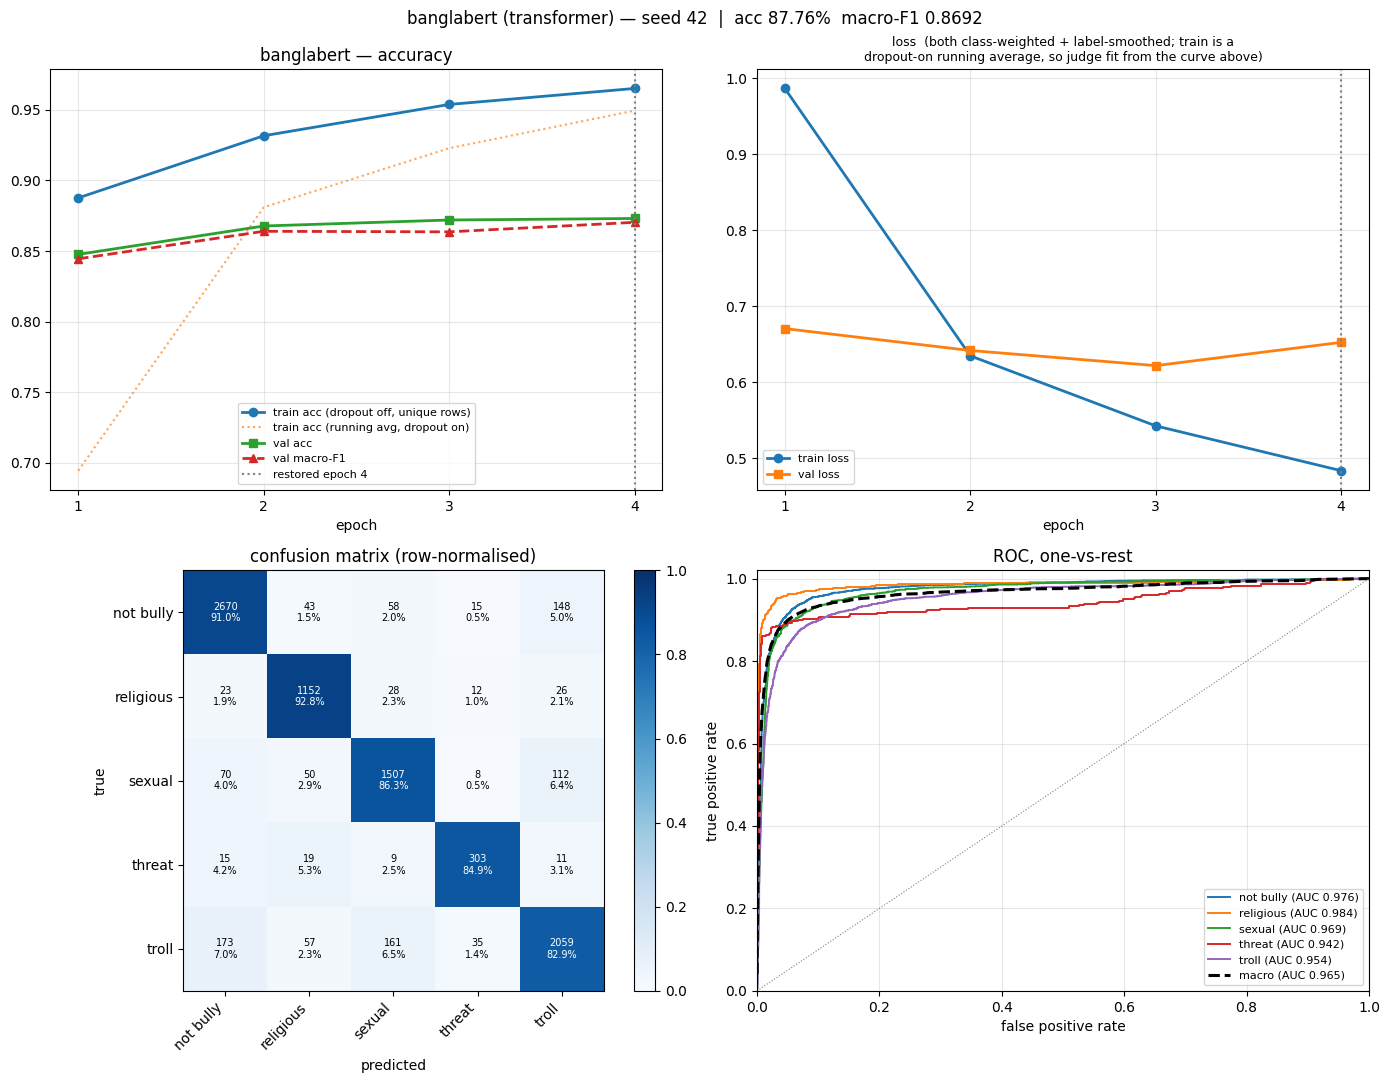

saved -> outputs\results_transformer_banglabert_s42.png


In [ ]:
AUC_TF["banglabert"] = report_one("banglabert")


muril — 8,764 unique test comments
accuracy 85.13%   macro-F1 0.8453
vs run row: 0.8453  (delta 0.00000)  OK

              precision    recall  f1-score   support

   not bully     0.8836    0.8797    0.8816      2934
   religious     0.8931    0.9154    0.9041      1241
      sexual     0.8302    0.8397    0.8349      1747
      threat     0.7550    0.8459    0.7979       357
       troll     0.8215    0.7948    0.8079      2485

    accuracy                         0.8513      8764
   macro avg     0.8367    0.8551    0.8453      8764
weighted avg     0.8515    0.8513    0.8512      8764

confusion matrix (counts):
           not bully  religious  sexual  threat  troll
not bully       2581         32      68      28    225
religious         29       1136      26      17     33
sexual            72         34    1467      15    159
threat            17         21       5     302     12
troll            222         49     201      38   1975

largest confusions:
    not bully -> troll

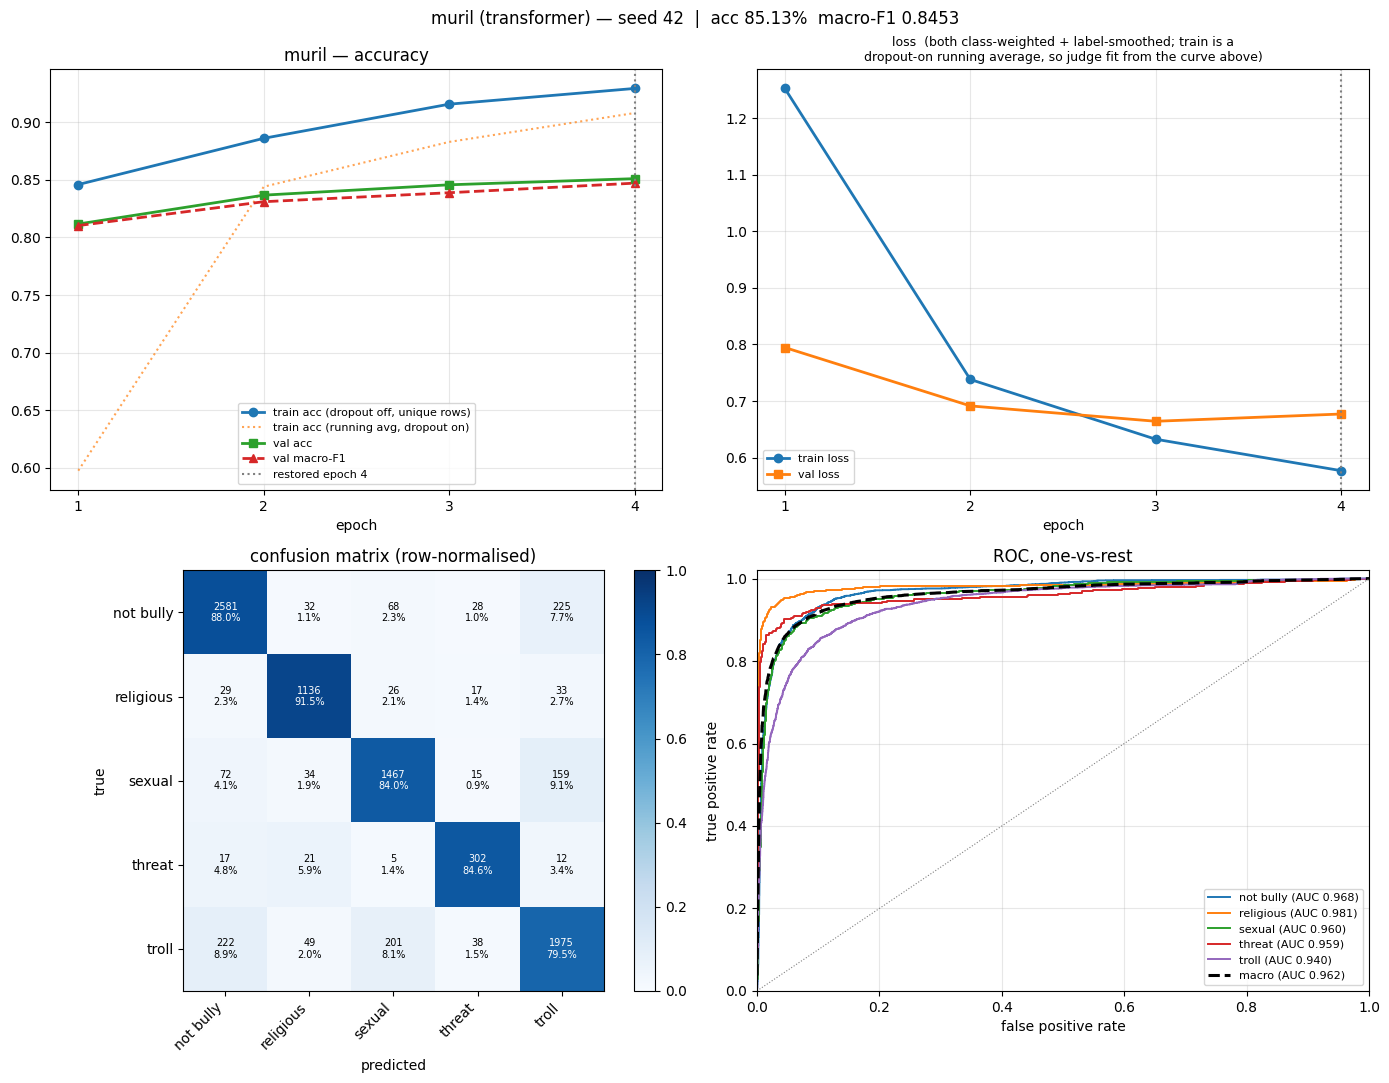

saved -> outputs\results_transformer_muril_s42.png


In [ ]:
AUC_TF["muril"] = report_one("muril")


xlmr — 8,764 unique test comments
accuracy 83.77%   macro-F1 0.8294
vs run row: 0.8294  (delta 0.00000)  OK

              precision    recall  f1-score   support

   not bully     0.8694    0.8712    0.8703      2934
   religious     0.8692    0.9049    0.8867      1241
      sexual     0.8191    0.8346    0.8268      1747
      threat     0.7277    0.8235    0.7727       357
       troll     0.8139    0.7690    0.7908      2485

    accuracy                         0.8377      8764
   macro avg     0.8199    0.8406    0.8294      8764
weighted avg     0.8378    0.8377    0.8374      8764

confusion matrix (counts):
           not bully  religious  sexual  threat  troll
not bully       2556         34      82      32    230
religious         26       1123      36      15     41
sexual            89         46    1458       8    146
threat            15         21       7     294     20
troll            254         68     197      55   1911

largest confusions:
        troll -> not bu

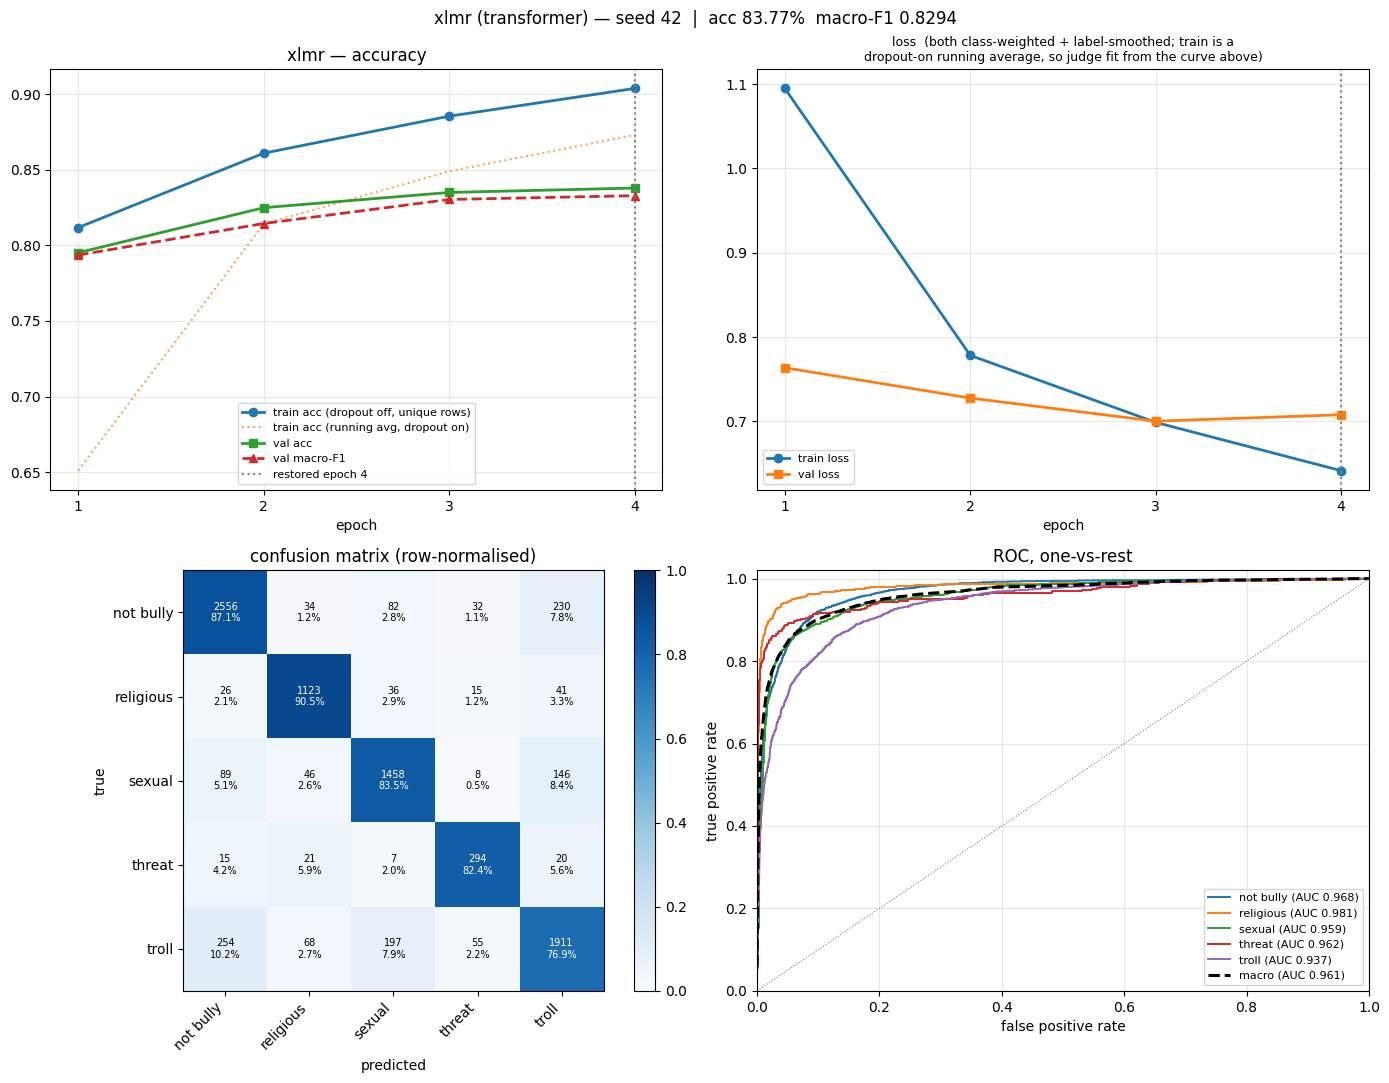

saved -> outputs\results_transformer_xlmr_s42.png


In [ ]:
AUC_TF["xlmr"] = report_one("xlmr")

In [ ]:
# ============================== CELL T6d =====================================
# Side-by-side AUC table once all three are done. This is the table that says
# whether the ranking is driven by one class or holds across all five.
#
# Note: AUC is threshold-free, so a model can win on AUC and lose on macro-F1.
# If that happens the winner separates the classes better but its argmax
# operating point is badly placed — a calibration problem, not a capacity one.
# -----------------------------------------------------------------------------
_done = [s for s in ("banglabert", "muril", "xlmr") if s in AUC_TF]
_miss = [s for s in ("banglabert", "muril", "xlmr") if s not in AUC_TF]
if _miss:
    print(f"not reported yet: {_miss} — run their T6 cells first\n")

if _done:
    auc_tbl = pd.DataFrame(
        {s: {**{id_to_label[i]: AUC_TF[s][i] for i in range(NUM_CLASSES)},
             "macro": AUC_TF[s]["macro"], "micro": AUC_TF[s]["micro"]}
         for s in _done}).T
    f1_tbl = pd.DataFrame(
        {s: {"macro_F1": RESULTS_TF[s]["macro_F1"],
             "test_acc": RESULTS_TF[s]["test_acc"]}
         for s in _done if s in RESULTS_TF}).T

    print("AUC one-vs-rest per class")
    print(auc_tbl.round(4).to_string())
    if len(f1_tbl):
        print("\nfor reference")
        print(f1_tbl.round(4).to_string())

    auc_tbl.to_csv(OUTDIR / f"auc_transformer_all_s{SEED}.csv")
    print(f"\nsaved -> {OUTDIR}/auc_transformer_all_s{SEED}.csv")

    if len(_done) == 3 and len(f1_tbl) == 3:
        best_auc = auc_tbl["macro"].idxmax()
        best_f1  = f1_tbl["macro_F1"].idxmax()
        if best_auc != best_f1:
            print(f"\nNOTE: {best_auc} wins on macro AUC but {best_f1} wins on "
                  f"macro-F1. Ranking depends on which you report, so say which "
                  f"one you are ranking by and why. Per-class thresholds tuned "
                  f"on val would likely close the gap.")
        else:
            print(f"\n{best_auc} wins on both macro AUC and macro-F1 — "
                  f"the ranking is not an artefact of the threshold.")


AUC one-vs-rest per class
            not bully  religious  sexual  threat   troll   macro   micro
banglabert     0.9762     0.9843  0.9688  0.9423  0.9538  0.9651  0.9576
muril          0.9678     0.9808  0.9598  0.9593  0.9402  0.9616  0.9538
xlmr           0.9681     0.9812  0.9585  0.9617  0.9375  0.9615  0.9543

for reference
            macro_F1  test_acc
banglabert    0.8692    0.8776
muril         0.8453    0.8513
xlmr          0.8294    0.8377

saved -> outputs/auc_transformer_all_s42.csv

banglabert wins on both macro AUC and macro-F1 — the ranking is not an artefact of the threshold.


3 prediction files found:
   transformer  banglabert     seed 42
   transformer  muril          seed 42
   transformer  xlmr           seed 42


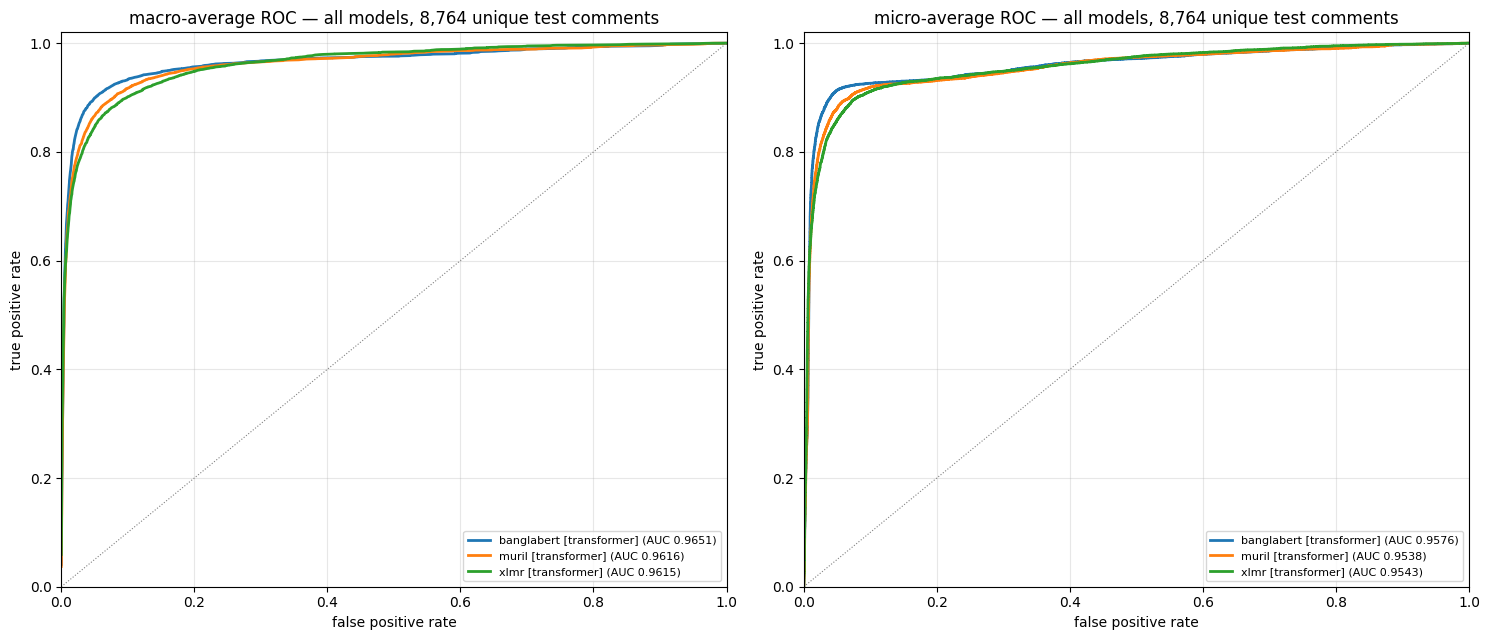

       algo      model  test_acc  macro_F1  macro_AUC
transformer banglabert    0.8776    0.8692     0.9651
transformer      muril    0.8513    0.8453     0.9616
transformer       xlmr    0.8377    0.8294     0.9615
saved -> roc_all_models.png, comparison_all_models.csv


In [ ]:
# ============================== CELL T7 ======================================
# All models on one ROC. Picks up EVERY prob_*.npy in OUTDIR, so the six
# word2vec/fasttext CNN-RNN runs appear here automatically once you have copied
# their .npy files across — that is the plot the comparison story hangs on.
# -----------------------------------------------------------------------------
def load_all_probs():
    out = {}
    for f in sorted(OUTDIR.glob("prob_*.npy")):
        stem = f.stem[len("prob_"):]
        rest, _, seed = stem.rpartition("_s")
        algo, _, model = rest.partition("_")
        p = np.load(f)
        if p.shape != (len(te_y), NUM_CLASSES):
            print(f"   skip {f.name}: shape {p.shape}, expected "
                  f"({len(te_y)}, {NUM_CLASSES})")
            continue
        if not np.allclose(p.sum(1), 1.0, atol=1e-3):
            print(f"   skip {f.name}: rows are not softmax probabilities "
                  f"(argmax predictions cannot make a ROC curve)")
            continue
        out[(algo, model, int(seed))] = p
    return out

PROB_ALL = load_all_probs()
print(f"{len(PROB_ALL)} prediction files found:")
for k in PROB_ALL:
    print(f"   {k[0]:<12} {k[1]:<14} seed {k[2]}")

yt = te_y[KEEP]
fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))
rows = []
cmap = plt.get_cmap("tab10")
for n, (k, p) in enumerate(sorted(PROB_ALL.items())):
    algo, model, seed = k
    lab = f"{model} [{algo}]"
    _f, _t, _A = roc_bundle(p[KEEP], yt)
    ax[0].plot(_f["macro"], _t["macro"], lw=2, color=cmap(n % 10),
               label=f"{lab} (AUC {_A['macro']:.4f})")
    ax[1].plot(_f["micro"], _t["micro"], lw=2, color=cmap(n % 10),
               label=f"{lab} (AUC {_A['micro']:.4f})")
    pr = p[KEEP].argmax(1)
    rows.append({"algo": algo, "model": model, "seed": seed,
                 "test_acc": float((pr == yt).mean()),
                 "macro_F1": f1_score(yt, pr, average="macro", zero_division=0),
                 "macro_AUC": _A["macro"], "micro_AUC": _A["micro"],
                 **{f"AUC_{id_to_label[i]}": _A[i] for i in range(NUM_CLASSES)},
                 **{f"F1_{id_to_label[i]}": v for i, v in
                    enumerate(f1_score(yt, pr, average=None,
                                       labels=range(NUM_CLASSES),
                                       zero_division=0))}})

for a, ttl in ((ax[0], "macro-average ROC"), (ax[1], "micro-average ROC")):
    a.plot([0, 1], [0, 1], color="grey", lw=.8, ls=":")
    a.set_xlim(0, 1); a.set_ylim(0, 1.02)
    a.set_xlabel("false positive rate"); a.set_ylabel("true positive rate")
    a.set_title(f"{ttl}-all models, {len(KEEP):,} unique test comments")
    a.legend(fontsize=8, loc="lower right"); a.grid(alpha=.3)
fig.tight_layout()
fig.savefig(OUTDIR / "roc_all_models.png", dpi=140, bbox_inches="tight")
plt.show()

CMP = pd.DataFrame(rows).sort_values("macro_F1", ascending=False)
CMP.to_csv(OUTDIR / "comparison_all_models.csv", index=False)
print(CMP[["algo", "model", "test_acc", "macro_F1", "macro_AUC"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("saved -> roc_all_models.png, comparison_all_models.csv")

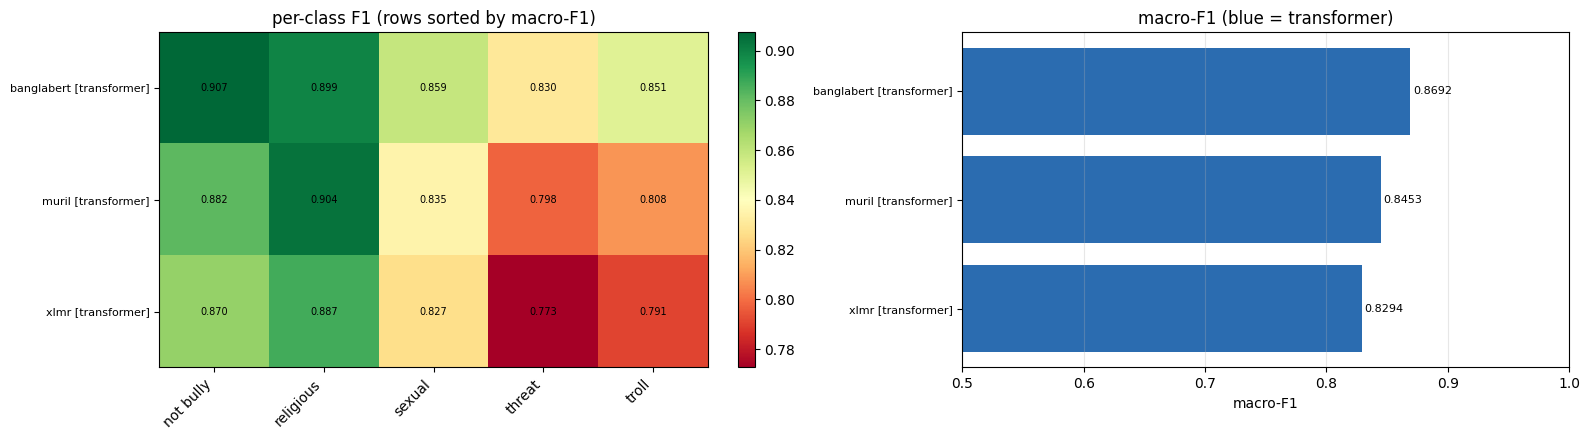


saved -> model_comparison.png, comparison_all_models.csv


In [ ]:
# ============================== CELL T8 ======================================
# Model comparison: per-class F1 heatmap, macro-F1 bars, and a bootstrap CI on
# the best-transformer-vs-best-embedding difference. The CI is the part that
# decides whether the gap is real: with 8,764 test comments, a 1-point macro-F1
# difference is inside the noise, so a bare table can make a tie look like a win.
# -----------------------------------------------------------------------------
if len(PROB_ALL) < 2:
    print("Only one model available — train more, or copy the CNN/RNN "
          "prob_*.npy files into OUTDIR, then re-run T7 and T8.")
else:
    lab_of  = {k: f"{k[1]} [{k[0]}]" for k in PROB_ALL}
    f1cols  = [f"F1_{l}" for l in id_to_label]
    heat    = CMP.set_index(CMP["model"] + " [" + CMP["algo"] + "]")[f1cols]

    fig, ax = plt.subplots(1, 2, figsize=(16, max(4.5, .55 * len(heat) + 2.5)))

    a  = ax[0]
    im = a.imshow(heat.values, cmap="RdYlGn", vmin=heat.values.min(),
                  vmax=heat.values.max(), aspect="auto")
    a.set_xticks(range(NUM_CLASSES)); a.set_xticklabels(id_to_label, rotation=45,
                                                       ha="right")
    a.set_yticks(range(len(heat))); a.set_yticklabels(heat.index, fontsize=8)
    for i in range(len(heat)):
        for j in range(NUM_CLASSES):
            a.text(j, i, f"{heat.values[i,j]:.3f}", ha="center", va="center",
                   fontsize=7)
    a.set_title("per-class F1 (rows sorted by macro-F1)")
    fig.colorbar(im, ax=a, fraction=.046)

    a = ax[1]
    y = np.arange(len(CMP))
    colors = ["#2b6cb0" if r == "transformer" else "#dd6b20"
              for r in CMP["algo"]]
    a.barh(y, CMP["macro_F1"], color=colors)
    a.set_yticks(y); a.set_yticklabels(
        (CMP["model"] + " [" + CMP["algo"] + "]").values, fontsize=8)
    a.invert_yaxis()
    for i, v in enumerate(CMP["macro_F1"]):
        a.text(v + .002, i, f"{v:.4f}", va="center", fontsize=8)
    a.set_xlim(min(.5, CMP["macro_F1"].min() - .05), 1.0)
    a.set_xlabel("macro-F1"); a.set_title("macro-F1 (blue = transformer)")
    a.grid(alpha=.3, axis="x")

    fig.tight_layout()
    fig.savefig(OUTDIR / "model_comparison.png", dpi=140, bbox_inches="tight")
    plt.show()

    # ---- paired bootstrap: is the winner actually ahead? --------------------
    def boot_diff(pa, pb, n=2000, seed=SEED):
        """Resample TEST COMMENTS, not predictions — both models see the same
           resample, which removes the shared test-set difficulty from the CI."""
        rs = np.random.RandomState(seed)
        a  = pa[KEEP].argmax(1); b = pb[KEEP].argmax(1)
        d  = np.empty(n)
        m  = len(KEEP)
        for i in range(n):
            ix = rs.randint(0, m, m)
            d[i] = (f1_score(yt[ix], a[ix], average="macro", zero_division=0) -
                    f1_score(yt[ix], b[ix], average="macro", zero_division=0))
        return d

    tf_keys  = [k for k in PROB_ALL if k[0] == "transformer"]
    emb_keys = [k for k in PROB_ALL if k[0] in ("word2vec", "fasttext")]
    if tf_keys and emb_keys:
        best_tf  = max(tf_keys,  key=lambda k: CMP.set_index(
            ["algo", "model", "seed"]).loc[k, "macro_F1"])
        best_emb = max(emb_keys, key=lambda k: CMP.set_index(
            ["algo", "model", "seed"]).loc[k, "macro_F1"])
        d  = boot_diff(PROB_ALL[best_tf], PROB_ALL[best_emb])
        lo, hi = np.percentile(d, [2.5, 97.5])
        print(f"\nbest transformer  {lab_of[best_tf]}")
        print(f"best embedding    {lab_of[best_emb]}")
        print(f"macro-F1 difference {d.mean()*100:+.2f} pp "
              f"[95% CI {lo*100:+.2f}, {hi*100:+.2f}]  "
              f"P(transformer better) = {(d > 0).mean()*100:.1f}%")
        print("CI crossing zero means the two are tied on this test set — report "
              "it as a tie, not a win." if lo < 0 < hi else
              "CI excludes zero — the difference is real at this sample size.")

        # ---- where does the winner actually gain? --------------------------
        pa = PROB_ALL[best_tf][KEEP].argmax(1)
        pb = PROB_ALL[best_emb][KEEP].argmax(1)
        both  = ((pa == yt) & (pb == yt)).sum()
        tf_o  = ((pa == yt) & (pb != yt)).sum()
        emb_o = ((pa != yt) & (pb == yt)).sum()
        nei   = ((pa != yt) & (pb != yt)).sum()
        print(f"\nagreement on {len(KEEP):,} comments:")
        print(f"   both right        {both:>6,} ({both/len(KEEP)*100:.1f}%)")
        print(f"   transformer only  {tf_o:>6,} ({tf_o/len(KEEP)*100:.1f}%)")
        print(f"   embedding only    {emb_o:>6,} ({emb_o/len(KEEP)*100:.1f}%)")
        print(f"   both wrong        {nei:>6,} ({nei/len(KEEP)*100:.1f}%)  "
              f"<- the irreducible part; the 2.82% contradictory-label floor "
              f"lives in here")

    CMP.to_csv(OUTDIR / "comparison_all_models.csv", index=False)
    print("\nsaved -> model_comparison.png, comparison_all_models.csv")

In [ ]:
# ============================= CELL T9-VERIFY ================================
# Reload from Drive and prove the saved model reproduces the reported number.
# Run once per model. This is the cell that turns a file into a backup.
# -----------------------------------------------------------------------------
def verify_saved(slug, tol=2e-3):
    m, tok, cfg = load_finetuned(slug)
    if m is None:
        print(f"{slug}: nothing saved at {model_dir(slug)}")
        return
    print(f"{slug}: reloaded from {model_dir(slug).name}")
    print(f"   stored dtype     {cfg.get('save_dtype')}")
    print(f"   normalisation    {cfg.get('text_normalisation')}")
    print(f"   label order      {cfg.get('id_to_label')}")
    assert cfg["id_to_label"] == id_to_label, \
        "saved label order differs from this session — every metric would be permuted"

    nz  = ((lambda a: [_bnorm(t) for t in a])
           if cfg.get("csebuetnlp_normalizer_used") else (lambda a: list(a)))
    ids = encode(tok, nz(te_txt))
    dl  = DataLoader(IdsDS(ids, te_y), batch_size=128,
                     collate_fn=make_collate(tok.pad_token_id))
    lf  = nn.CrossEntropyLoss(
              weight=torch.tensor(cw, dtype=torch.float32, device=DEV),
              label_smoothing=LABEL_SMOOTH)
    _, pred, prob = evaluate(m, dl, lf, want_prob=True)

    yt   = te_y[KEEP]
    f1_r = f1_score(yt, pred[KEEP], average="macro", zero_division=0)
    f1_o = RESULTS_TF[slug]["macro_F1"] if slug in RESULTS_TF else float("nan")
    print(f"   reloaded macro-F1 {f1_r:.4f}   original {f1_o:.4f}   "
          f"delta {abs(f1_r-f1_o):.5f}")

    if slug in PROBS_TF:
        mad  = float(np.abs(prob - PROBS_TF[slug]).max())
        flip = int((prob.argmax(1) != PROBS_TF[slug].argmax(1)).sum())
        print(f"   max prob deviation {mad:.2e} | argmax flips {flip}/{len(te_y)}")

    ok = np.isnan(f1_o) or abs(f1_r - f1_o) <= tol
    print("   VERIFIED" if ok else f"   *** MISMATCH > {tol}")
    if not ok:
        print("   Usual cause: the normalizer flag in inference_config.json does "
              "not match how the text was preprocessed at training time.")
    print("   fp16 storage rounds probabilities at ~1e-3, so a handful of argmax "
          "flips on near-ties is expected and harmless; a macro-F1 shift beyond "
          f"{tol} is not.")
    del m; gc.collect(); torch.cuda.empty_cache()

for _s in list(RESULTS_TF):
    verify_saved(_s)

banglabert: reloaded from banglabert_s42
   stored dtype     float16
   normalisation    NFC + csebuetnlp.normalizer
   label order      ['not bully', 'religious', 'sexual', 'threat', 'troll']
   reloaded macro-F1 0.8693   original 0.8692   delta 0.00007
   max prob deviation 5.79e-03 | argmax flips 1/11999
   VERIFIED
   fp16 storage rounds probabilities at ~1e-3, so a handful of argmax flips on near-ties is expected and harmless; a macro-F1 shift beyond 0.002 is not.
muril: reloaded from muril_s42
   stored dtype     float16
   normalisation    NFC
   label order      ['not bully', 'religious', 'sexual', 'threat', 'troll']
   reloaded macro-F1 0.8452   original 0.8453   delta 0.00013
   max prob deviation 8.82e-03 | argmax flips 8/11999
   VERIFIED
   fp16 storage rounds probabilities at ~1e-3, so a handful of argmax flips on near-ties is expected and harmless; a macro-F1 shift beyond 0.002 is not.
xlmr: reloaded from xlmr_s42
   stored dtype     float16
   normalisation    NFC
   la

In [ ]:
import shutil

# ============================= CELL T10-MIRROR ===============================
# Copy the cheap-but-irreplaceable artifacts to Drive. Run after every model and
# again after T7/T8. 2 MiB of prediction files regenerate every plot and table in
# T6, T7 and T8 without a GPU — this is the backup that actually matters.
# -----------------------------------------------------------------------------
def mirror(verbose=True):
    n = 0
    tot = 0
    for pat in ("prob_*.npy", "history_*.json", "*.csv", "*.png"):
        for f in OUTDIR.glob(pat):
            shutil.copy2(f, MIRROR / f.name)
            n += 1; tot += f.stat().st_size
            if verbose:
                print(f"   {f.name:<44} {f.stat().st_size/1024:>8.0f} KiB")
    print(f"mirrored {n} files ({tot/1024**2:.2f} MiB) -> {MIRROR}")
    return n

mirror()

print("\nTo rebuild every result later without a GPU: mount Drive, set "
      "OUTDIR=MIRROR, load the CSVs from nb_dataset to rebuild KEEP, then run "
      "T7 and T8. It reads only prob_*.npy.")


   prob_transformer_banglabert_s42.npy               234 KiB
   prob_transformer_muril_s42.npy                    234 KiB
   prob_transformer_xlmr_s42.npy                     234 KiB
   history_banglabert_s42.json                         1 KiB
   history_muril_s42.json                              1 KiB
   history_xlmr_s42.json                               1 KiB
   auc_transformer_all_s42.csv                         0 KiB
   comparison_all_models.csv                           1 KiB
   confusion_transformer_banglabert_s42.csv            0 KiB
   confusion_transformer_muril_s42.csv                 0 KiB
   confusion_transformer_xlmr_s42.csv                  0 KiB
   report_transformer_banglabert_s42.csv               1 KiB
   report_transformer_muril_s42.csv                    1 KiB
   report_transformer_xlmr_s42.csv                     1 KiB
   symptom_clusters.csv                                1 KiB
   symptom_correlation.csv                            75 KiB
   symptom_co_occurrence